In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# 1. Load dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print("Initial Shape:", df.shape)

# Drop primary key identifier (prevents synthetic correlation)
df = df.drop(columns=['id'])

# Remove the single 'Other' row in gender to prevent sparse single-sample dummy columns
df = df[df['gender'] != 'Other']

print("Cleaned Baseline Shape:", df.shape)

Initial Shape: (5110, 12)
Cleaned Baseline Shape: (5109, 11)


In [6]:
X = df.drop(columns=['stroke'])
y = df['stroke']

# Stratify preserves the ~4.9% positive stroke ratio across both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Train split: {X_train.shape}, Test split: {X_test.shape}")

Train split: (3576, 10), Test split: (1533, 10)


/tmp/ipykernel_889/2032439297.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, ax=axes[0], palette='Blues_d')
/tmp/ipykernel_889/2032439297.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])


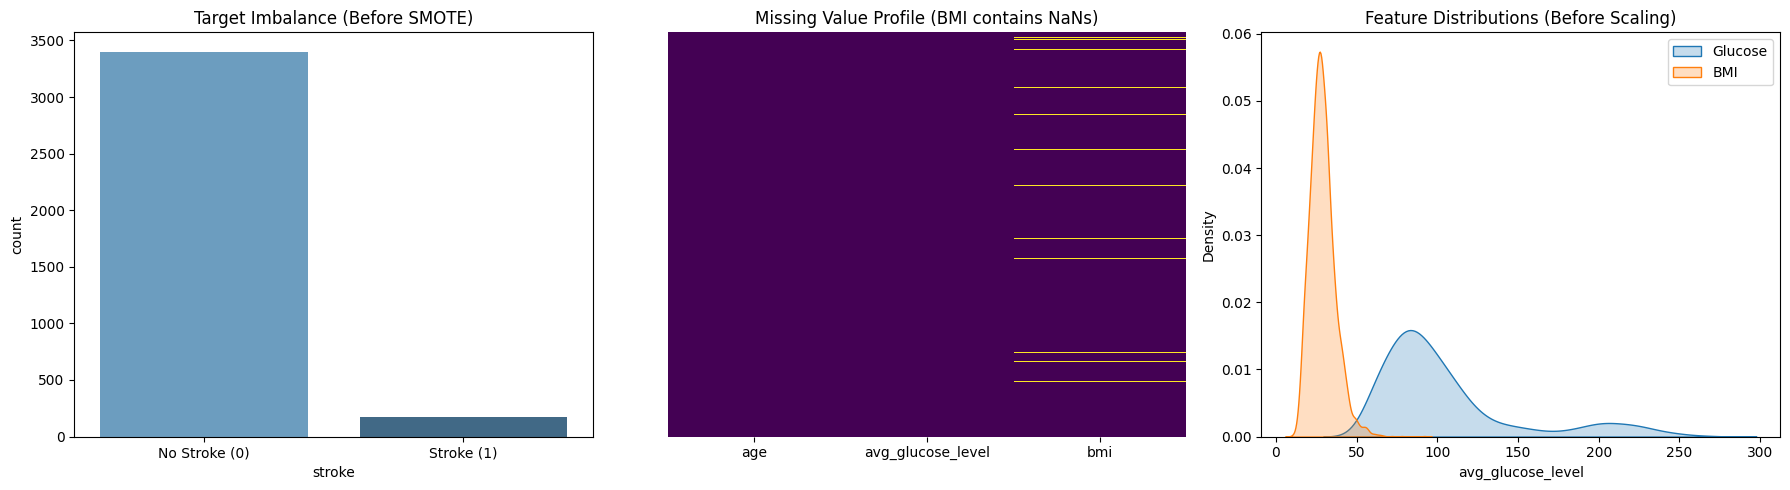

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Target Imbalance
sns.countplot(x=y_train, ax=axes[0], palette='Blues_d')
axes[0].set_title('Target Imbalance (Before SMOTE)')
axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])

# 2. Missing Value Heatmap
sns.heatmap(X_train[['age', 'avg_glucose_level', 'bmi']].isnull(), cbar=False, yticklabels=False, ax=axes[1], cmap='viridis')
axes[1].set_title('Missing Value Profile (BMI contains NaNs)')

# 3. Numeric Skewness
sns.kdeplot(X_train['avg_glucose_level'], label='Glucose', ax=axes[2], fill=True)
sns.kdeplot(X_train['bmi'], label='BMI', ax=axes[2], fill=True)
axes[2].set_title('Feature Distributions (Before Scaling)')
axes[2].legend()

plt.tight_layout()
plt.show()

In [8]:
median_bmi = X_train['bmi'].median()
print(f"Calculated Training Median BMI: {median_bmi:.2f}")

X_train['bmi'] = X_train['bmi'].fillna(median_bmi)
X_test['bmi'] = X_test['bmi'].fillna(median_bmi)

Calculated Training Median BMI: 27.90


In [9]:
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

# Guarantee identical column layout across train and test
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [10]:
scaler = StandardScaler()
numeric_cols = ['age', 'avg_glucose_level', 'bmi']

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [11]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("Balanced Training Distribution:\n", y_train_balanced.value_counts())

Balanced Training Distribution:
 stroke
0    3402
1    3402
Name: count, dtype: int64


/tmp/ipykernel_889/4271858522.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_balanced, ax=axes[0], palette='Greens_d')
/tmp/ipykernel_889/4271858522.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])


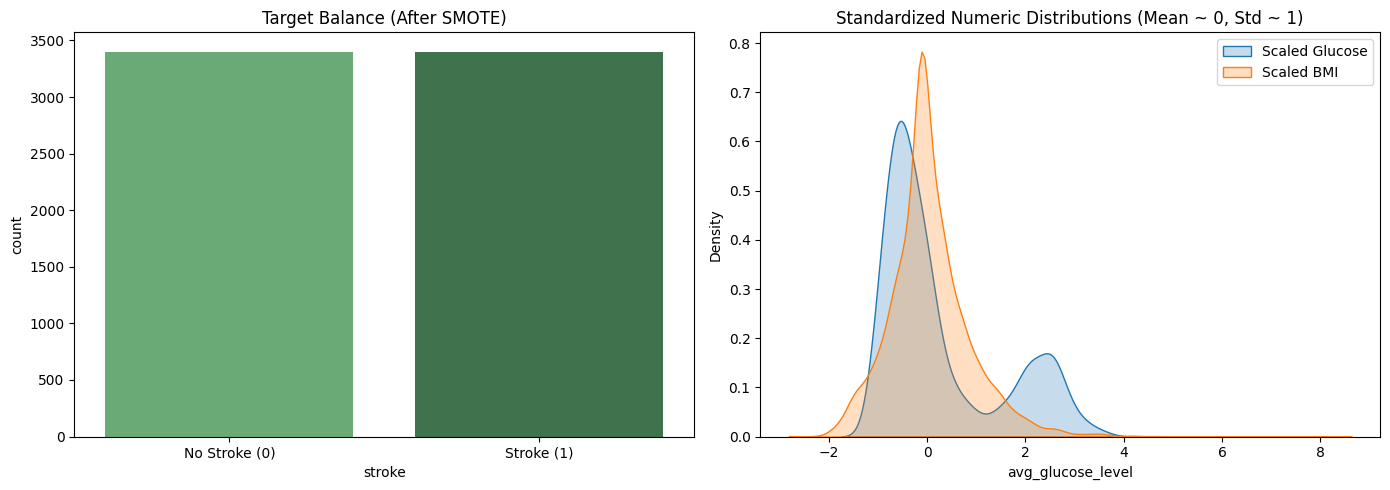

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Post-SMOTE Balance
sns.countplot(x=y_train_balanced, ax=axes[0], palette='Greens_d')
axes[0].set_title('Target Balance (After SMOTE)')
axes[0].set_xticklabels(['No Stroke (0)', 'Stroke (1)'])

# 2. Scaled Distributions
sns.kdeplot(X_train_balanced['avg_glucose_level'], label='Scaled Glucose', ax=axes[1], fill=True)
sns.kdeplot(X_train_balanced['bmi'], label='Scaled BMI', ax=axes[1], fill=True)
axes[1].set_title('Standardized Numeric Distributions (Mean ~ 0, Std ~ 1)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
train_processed = pd.concat([X_train_balanced, y_train_balanced], axis=1)
test_processed = pd.concat([X_test, y_test], axis=1)

train_processed.to_csv('cleaned_train_stroke_data.csv', index=False)
test_processed.to_csv('cleaned_test_stroke_data.csv', index=False)

print("Saved 'cleaned_train_stroke_data.csv' and 'cleaned_test_stroke_data.csv'")

Saved 'cleaned_train_stroke_data.csv' and 'cleaned_test_stroke_data.csv'
